## Step 1 – Install libraries
Run once. Brings all the tools into our project.

In [1]:
%pip install --upgrade langchain-community langchain-text-splitters langchain-ollama langchain-groq langgraph langgraph-checkpoint-sqlite chromadb pypdf python-dotenv rank_bm25 sentence-transformers tavily-python

     ---------------------------------------- 0.0/61.0 kB ? eta -:--:--
     -------------------- ------------------- 30.7/61.0 kB ? eta -:--:--
     -------------------------------------- 61.0/61.0 kB 804.9 kB/s eta 0:00:00
  Using cached tiktoken-0.14.0-cp311-cp311-win_amd64.whl.metadata (6.8 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached regex-2026.9.29-cp311-cp311-win_amd64.whl.metadata (41 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached markupsafe-3.0.4-cp311-cp311-win_amd64.whl.metadata (2.8 kB)
   ---------------------------------------- 0.0/260.8 kB ? eta -:--:--
   --------- ------------------------------ 61.4/260.8 kB 1.7 MB/s eta 0:00:01
   --------- ------------------------------ 61.4/260.8 kB 1.7 MB/s eta 0:00:01
   -------------- ----------------------- 102.4/260.8 kB 737.3 kB/s eta 0:00:01
   ---------------------------- -----


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2 – Imports
Take the tools out of the box.

In [2]:
import os                                                       # read keys from .env
import re                                                       # read "VERDICT: ..." lines from LLM replies
import time                                                     # wait before retrying
import sqlite3                                                  # chat memory file
import operator                                                 # operator.add = history keeps growing
from typing import TypedDict, Annotated                         # shape of our state
from dotenv import load_dotenv                                  # reads the .env file
from langchain_community.document_loaders import PyPDFLoader   # reads the PDF
from langchain_text_splitters import RecursiveCharacterTextSplitter  # cuts text into chunks
from langchain_ollama import OllamaEmbeddings                   # text -> numbers (local)
from langchain_community.vectorstores import Chroma             # vector DB  (search by MEANING)
from langchain_community.retrievers import BM25Retriever        # BM25       (search by WORDS)
from sentence_transformers import CrossEncoder                  # re-ranker  (picks the best chunks)
from langchain_groq import ChatGroq                             # LLMs on Groq
from groq import RateLimitError                                 # "too many requests" error
from tavily import TavilyClient                                 # web search
from langchain_core.messages import SystemMessage, HumanMessage # message types
from langgraph.graph import StateGraph, START, END              # graph builder
from langgraph.checkpoint.sqlite import SqliteSaver             # saves memory to SQLite

C:\Users\ACER\AppData\Local\Temp\ipykernel_19264\4091826320.py:8: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader   # reads the PDF
c:\Users\ACER\Downloads\Coding\RESUME_PROJECT\Advanced_Rag\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 3 – Settings (our control panel)
All numbers in one place, so students can change them and see what happens.

In [3]:
load_dotenv(override=True)                                      # loads GROQ_API_KEY and TAVILY_API_KEY

PDF_FILE         = "text_medical.pdf"                           # our health book
OLLAMA_URL       = "http://localhost:11434"                     # Ollama (embeddings) runs here
CHROMA_FOLDER    = "./chroma_db_advanced"                       # vector DB folder

NUM_QUERIES      = 3                                            # multi-query: extra versions of the question
VECTOR_K         = 4                                            # chunks per query from the vector DB
BM25_K           = 4                                            # chunks per query from BM25
WEB_RESULTS      = 3                                            # pages from the web
RERANK_TOP       = 5                                            # re-ranker keeps only the best 5

MAX_ANSWER_TRIES = 2                                            # LLM may write the answer at most 2 times (1 fix)
MAX_SEARCH_TRIES = 2                                            # we may search at most 2 times (1 search again)
HISTORY_TURNS    = 3                                            # last 3 Q/A pairs go to the LLM

TAVILY_KEY = os.environ.get("TAVILY_API_KEY", "")               # no key -> web search is skipped
web_client = TavilyClient(api_key=TAVILY_KEY) if TAVILY_KEY else None

print("Web search:", "ON" if web_client else "OFF (only book)")

Web search: OFF (only book)


## Step 4 – Load the PDF and cut it into chunks
Big book → small pieces (chunks) of 1000 characters.

In [4]:
documents = PyPDFLoader(PDF_FILE).load()                        # one Document per page
splitter  = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)   # 200 chars shared between neighbours
chunks    = splitter.split_documents(documents)                 # cut every page

print("Pages:", len(documents), "| Chunks:", len(chunks))

Pages: 56 | Chunks: 257


## Step 5 – Vector database (search by meaning)
First run: store the chunks. Next runs: just load the folder.

In [5]:
embedding_model = OllamaEmbeddings(model="embeddinggemma", base_url=OLLAMA_URL)

if not os.path.exists(CHROMA_FOLDER):                           # first run
    vectorstore = Chroma.from_documents(chunks, embedding_model, persist_directory=CHROMA_FOLDER)
    print("Stored", vectorstore._collection.count(), "chunks")
else:                                                           # next runs
    vectorstore = Chroma(persist_directory=CHROMA_FOLDER, embedding_function=embedding_model)
    print("Loaded", vectorstore._collection.count(), "chunks")

C:\Users\ACER\AppData\Local\Temp\ipykernel_19264\414984981.py:7: LangChainDeprecationWarning: The class `Chroma` was deprecated in LangChain 0.2.9 and will be removed in 1.0. An updated version of the class exists in the `langchain-chroma package and should be used instead. To use it run `pip install -U `langchain-chroma` and import as `from `langchain_chroma import Chroma``.
  vectorstore = Chroma(persist_directory=CHROMA_FOLDER, embedding_function=embedding_model)


Loaded 257 chunks


## Step 6 – BM25 (search by words) + Re-ranker
* **BM25** finds chunks that contain the *same words* (good for names like "ORS", "malaria").
* **Re-ranker** reads (question, chunk) pairs and gives each a relevance score.

In [6]:
bm25   = BM25Retriever.from_documents(chunks)                   # keyword index (in memory)
bm25.k = BM25_K

reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2") # small model (~90 MB, downloads once)
print("BM25 + re-ranker ready")

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 2577.85it/s]


BM25 + re-ranker ready


## Step 7 – The LLMs (3 brains)
| Brain | Job |
|---|---|
| `llm` (big) | rewrite question, make queries, write answers |
| `router_llm` (small) | one word: health or chat? |
| `check_llm` (different family) | checks the answer (self-corrector) |

In [7]:
llm = ChatGroq(model="openai/gpt-oss-120b", temperature=0.1, max_tokens=1500, reasoning_effort="low")    # writer
router_llm = ChatGroq(model="openai/gpt-oss-20b", temperature=0.0, max_tokens=300, reasoning_effort="low")  # quick router
check_llm = ChatGroq(model="qwen/qwen3.8-27b", temperature=0.0, max_tokens=900, reasoning_effort="none")  # checker
print("LLMs ready")

LLMs ready


## Step 8 – State (the notebook every node reads and writes)

In [8]:
class AdvState(TypedDict):
    question: str                                               # user's message
    route: str                                                  # "health" or "chat"
    rewritten: str                                              # clean question (query_rewriter)
    queries: list                                               # all search queries (multi_query_generator)
    candidates: list                                            # everything found (retrieval_layer)
    top_chunks: list                                            # best chunks (re_ranker)
    context: str                                                # chunks joined for the prompt (augment_context)
    generation: str                                             # the answer
    verdict: str                                                # "correct" / "refine" / "retrieve_again"
    feedback: str                                               # what the checker wants fixed
    answer_tries: int                                           # how many times the LLM wrote an answer
    search_tries: int                                           # how many times we searched
    history: Annotated[list, operator.add]                      # chat memory (grows, saved in SQLite)

## Step 9 – Prompts (job description for each brain)

In [9]:
SAFETY_LINE = "This is general guidance, not a diagnosis; if you are worried or it gets worse, please see a health worker."

# 1. route_question: health or chat?
ROUTE_PROMPT = """Is this message a health question? Reply with ONE word: health or chat.
health - health, body, illness, symptoms, medicine, first aid, nutrition, hygiene, pregnancy, children's health,
         or a follow-up / reply about an earlier health topic in the CHAT HISTORY ("what about children?", "3 days")
chat   - everything else: greetings, thanks, small talk, name, "who are you", "do you remember me",
         and off-topic questions (sports, news, coding, maths, movies, jokes)
The message can be in English, Hindi, Hinglish or Punjabi."""

# 2. direct_answer: friendly reply, no search
DIRECT_PROMPT = """You are a friendly Village Health Guide Assistant.
Reply warmly in 1 to 3 short sentences, in the same language as the user. No bold, no lists.
Use the CHAT HISTORY to remember the user's name and earlier questions.
If the message is off-topic (sports, news, coding, jokes), politely say you only help with health questions.
Never give health facts here."""

# 3. query_rewriter: clean and expand the question
REWRITE_PROMPT = """Rewrite the user's message into ONE clear English question for searching a village health book.
- Fix spelling, expand short forms (BP -> blood pressure), use book words ("loose motions" -> diarrhea).
- Translate Hindi / Hinglish / Punjabi to English.
- If it is a follow-up, use the CHAT HISTORY to add the missing topic.
- If FEEDBACK is given, the last search failed: use it to write a better question.
- Reply with the question only."""

# 4. multi_query_generator: same question, different angles
MULTI_QUERY_PROMPT = f"""Write {NUM_QUERIES} short search queries for the QUESTION, each from a different angle
(symptoms / what to do / danger signs). One query per line, no numbers, no extra text."""

# 5. LLM: answer only from the context, like a caring human
ANSWER_PROMPT = f"""You are a caring Village Health Guide Assistant. Talk like a kind health worker speaking to a neighbour.
Take facts ONLY from the CONTEXT (each block starts with [page N] or [web: link]). Never use your own knowledge.

RULES
- Do NOT add numbers, doses, medicine names or warnings that are not in the CONTEXT.
- Do NOT change who a medicine is for (children / adults / pregnant women).
- Include danger signs (when to see a health worker) if the CONTEXT has them.
- If the CONTEXT does not answer the question, say so honestly and kindly.
- If FEEDBACK is given, fix exactly those problems.

STYLE
- If someone is unwell, start with one short caring line. Use the user's name once if you know it.
- Simple words, 3 to 6 short sentences, one paragraph, same language as the user. No bold, no lists.
- End with one short follow-up question when it helps.
- Then on a NEW line: {SAFETY_LINE}
- Then on a NEW line: Source: page 28, web: https://example.org"""

# 6. self_corrector: check the answer and decide
CHECK_PROMPT = f"""You check an ANSWER against its CONTEXT. Ignore the line "{SAFETY_LINE}" and the "Source:" line.
1. For each claim in the ANSWER write SUPPORTED or UNSUPPORTED (must be clearly in the CONTEXT).
2. Decide:
   correct        - all claims supported AND it tells the user what to do
   refine         - the CONTEXT has the info, but the ANSWER has mistakes or missed parts
   retrieve_again - the CONTEXT does not have the info needed
Output:
SUPPORTED - <claim>
UNSUPPORTED - <claim>
FEEDBACK: <one sentence: what to fix or what is missing>
VERDICT: correct | refine | retrieve_again"""

## Step 10 – Helpers (small tools the nodes use)
| Helper | Job |
|---|---|
| `ask_llm` | call an LLM, wait & retry if Groq says "too many requests" |
| `recent_history` | last 3 chats as text |
| `with_page` | chunk → `[page N]` + text |
| `tidy_answer` | answer → safety line → source, each on its own line |

In [10]:
def ask_llm(model, system_prompt, user_text, tries=3, wait=25):
    for attempt in range(tries):
        try:
            reply = model.invoke([SystemMessage(content=system_prompt), HumanMessage(content=user_text)])
            return (reply.content or "").strip()
        except RateLimitError:                                  # Groq per-minute limit
            if attempt == tries - 1:
                raise
            print(f"   [wait] rate limit, waiting {wait}s...")
            time.sleep(wait)


def recent_history(state):
    lines = state.get("history", [])[-HISTORY_TURNS * 2:]       # 2 lines per turn
    return "\n".join(lines) if lines else "(no earlier messages)"


def with_page(doc):
    return f"[page {doc.metadata.get('page', 0) + 1}]\n{doc.page_content}"   # PDF pages start at 0


def tidy_answer(answer):
    text = answer.replace(SAFETY_LINE, "").strip()              # remove the safety line wherever it is
    cut  = text.lower().rfind("source:")                        # split off the "Source:" part
    body, source = (text[:cut].strip(), text[cut:].strip()) if cut != -1 else (text, "")
    return "\n".join(p for p in [body, SAFETY_LINE, source] if p)

## Step 11 – Nodes (the workers – each does ONE job)
Every node follows the same pattern:
```
1. READ from state   2. DO one job   3. RETURN what changed
```

In [11]:
# NODE 1 route_question: health question or just chat?
def route_question_node(state):
    text  = f"CHAT HISTORY:\n{recent_history(state)}\n\nMESSAGE: {state['question']}"
    reply = ask_llm(router_llm, ROUTE_PROMPT, text)
    route = "chat" if reply.lower().startswith("chat") else "health"    # unsure -> health
    print("   [route]    ", route)
    return {"route": route}


# NODE 2 direct_answer: greetings / small talk / off-topic -> reply without searching
def direct_answer_node(state):
    text  = f"CHAT HISTORY:\n{recent_history(state)}\n\nMESSAGE: {state['question']}"
    reply = ask_llm(llm, DIRECT_PROMPT, text)
    return {"generation": reply or "Hello! How can I help you with a health question today?"}


# NODE 3 query_rewriter: messy message -> one clear English question
def query_rewriter_node(state):
    text = (f"CHAT HISTORY:\n{recent_history(state)}\n\nMESSAGE: {state['question']}"
            f"\n\nFEEDBACK: {state['feedback'] or '(none)'}")
    rewritten = ask_llm(llm, REWRITE_PROMPT, text) or state["question"]
    print("   [rewrite]  ", rewritten)
    return {"rewritten": rewritten, "search_tries": state["search_tries"] + 1}


# NODE 4 multi_query_generator: 1 question -> 4 queries (different angles)
def multi_query_node(state):
    reply = ask_llm(llm, MULTI_QUERY_PROMPT, f"QUESTION: {state['rewritten']}")
    extra = [line.strip("-• ").strip() for line in reply.splitlines() if line.strip()][:NUM_QUERIES]
    queries = [state["rewritten"]] + extra
    print("   [queries]  ", queries)
    return {"queries": queries}


# NODE 5 retrieval_layer: HYBRID search = vector DB + BM25 (+ web)
def retrieval_node(state):
    found = []
    for q in state["queries"]:
        found += [with_page(d) for d in vectorstore.similarity_search(q, k=VECTOR_K)]   # by meaning
        found += [with_page(d) for d in bm25.invoke(q)]                               # by words
    if web_client:                                                                     # by web
        for r in web_client.search(state["rewritten"], max_results=WEB_RESULTS)["results"]:
            found.append(f"[web: {r['url']}]\n{r['content']}")
    unique = list(dict.fromkeys(found))                         # remove duplicates
    print(f"   [retrieve]  {len(found)} found -> {len(unique)} unique")
    return {"candidates": unique}


# NODE 6 re_ranker: score every chunk against the question, keep the best 5
def re_ranker_node(state):
    pairs  = [(state["rewritten"], chunk) for chunk in state["candidates"]]
    scores = reranker.predict(pairs)                            # one score per chunk (higher = better)
    ranked = sorted(zip(scores, state["candidates"]), key=lambda pair: pair[0], reverse=True)
    top    = [chunk for score, chunk in ranked[:RERANK_TOP]]
    print("   [re-rank]   kept:", ", ".join(c.split("\n")[0] for c in top))
    return {"top_chunks": top}


# NODE 7 augment_context: join the best chunks into one text for the prompt
def augment_context_node(state):
    return {"context": "\n\n".join(state["top_chunks"])}


# NODE 8 LLM: write the answer (or fix it, if the checker gave feedback)
def llm_node(state):
    text = (f"CHAT HISTORY:\n{recent_history(state)}\n\n"
            f"USER'S MESSAGE: {state['question']}\nQUESTION: {state['rewritten']}\n\n"
            f"CONTEXT:\n{state['context']}")
    if state["verdict"] == "refine":                            # second try: show what to fix
        text += f"\n\nFEEDBACK: {state['feedback']}\n\nPREVIOUS ANSWER:\n{state['generation']}"
    reply = ask_llm(llm, ANSWER_PROMPT, text)
    print("   [LLM]       answer written")
    return {"generation": tidy_answer(reply), "answer_tries": state["answer_tries"] + 1}


# NODE 9 self_corrector: check the answer -> correct / refine / retrieve_again
def self_corrector_node(state):
    text  = f"ANSWER:\n{state['generation']}\n\nCONTEXT:\n{state['context']}"
    reply = ask_llm(check_llm, CHECK_PROMPT, text)
    verdict  = re.search(r"VERDICT:\s*(correct|refine|retrieve_again)", reply, re.IGNORECASE)
    feedback = re.search(r"FEEDBACK:\s*(.+)", reply, re.IGNORECASE)
    verdict  = verdict.group(1).lower() if verdict else "refine"
    print("   [check]    ", verdict)
    return {"verdict": verdict, "feedback": feedback.group(1).strip() if feedback else ""}


# NODE 10 final_answer: answer passed the check
def final_answer_node(state):
    print("   [final]     answer accepted")
    return {}


# NODE 11 no_answer_found: all tries used, still not correct -> be honest
def no_answer_found_node(state):
    print("   [not_found] giving up safely")
    return {"generation": "I don't know based on the available sources. Please ask a health worker or visit a clinic."}


# NODE 12 save_memory: remember this Q/A
def save_memory_node(state):
    return {"history": [f"User: {state['question']}", f"Assistant: {state['generation']}"]}

## Step 12 – Routers (decide the next node)

In [12]:
def after_route(state):                                         # chat -> direct_answer, health -> RAG
    return "direct_answer" if state["route"] == "chat" else "query_rewriter"


def after_check(state):
    if state["verdict"] == "correct":
        return "final_answer"                                   # ✅ good answer
    if state["verdict"] == "refine" and state["answer_tries"] < MAX_ANSWER_TRIES:
        return "LLM"                                            # 🔁 small loop: fix the answer
    if state["search_tries"] < MAX_SEARCH_TRIES:
        return "query_rewriter"                                 # 🔁 big loop: search again with feedback
    return "no_answer_found"                                    # ❌ tries used up

## Step 13 – Build the graph (connect the workers with arrows)

In [13]:
builder = StateGraph(AdvState)

builder.add_node("route_question", route_question_node)
builder.add_node("direct_answer", direct_answer_node)
builder.add_node("query_rewriter", query_rewriter_node)
builder.add_node("multi_query_generator", multi_query_node)
builder.add_node("retrieval_layer", retrieval_node)
builder.add_node("re_ranker", re_ranker_node)
builder.add_node("augment_context", augment_context_node)
builder.add_node("LLM", llm_node)
builder.add_node("self_corrector", self_corrector_node)
builder.add_node("final_answer", final_answer_node)
builder.add_node("no_answer_found", no_answer_found_node)
builder.add_node("save_memory", save_memory_node)

builder.add_edge(START, "route_question")
builder.add_conditional_edges("route_question", after_route, ["direct_answer", "query_rewriter"])
builder.add_edge("direct_answer", "save_memory")

builder.add_edge("query_rewriter", "multi_query_generator")
builder.add_edge("multi_query_generator", "retrieval_layer")
builder.add_edge("retrieval_layer", "re_ranker")
builder.add_edge("re_ranker", "augment_context")
builder.add_edge("augment_context", "LLM")
builder.add_edge("LLM", "self_corrector")
builder.add_conditional_edges("self_corrector", after_check,
                              ["final_answer", "LLM", "query_rewriter", "no_answer_found"])

builder.add_edge("final_answer", "save_memory")
builder.add_edge("no_answer_found", "save_memory")
builder.add_edge("save_memory", END)

memory       = SqliteSaver(sqlite3.connect("advanced_memory.db", check_same_thread=False))
advanced_rag = builder.compile(checkpointer=memory)
print("Advanced RAG ready!")

Advanced RAG ready!


## Step 14 – Draw the graph

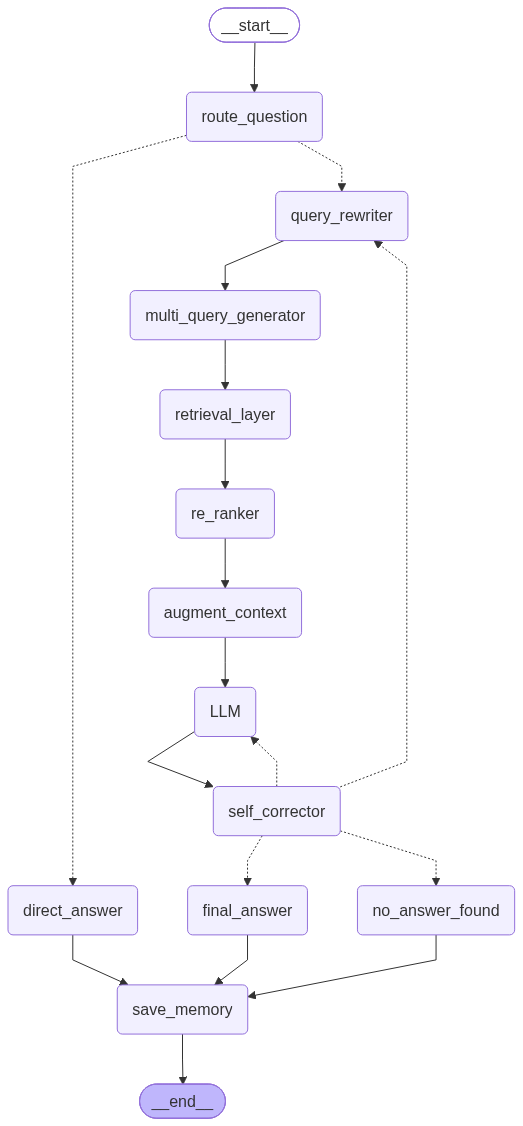

In [14]:
from IPython.display import Image, display

try:
    display(Image(advanced_rag.get_graph().draw_mermaid_png()))
except Exception:
    print(advanced_rag.get_graph().draw_mermaid())

## Step 15 – Ask function
Resets the per-question values; `history` is NOT reset, so the bot remembers the chat.

In [15]:
def ask(question, thread="chat1"):
    config = {"configurable": {"thread_id": thread}, "recursion_limit": 40}
    start  = {"question": question, "route": "", "rewritten": "", "queries": [], "candidates": [],
              "top_chunks": [], "context": "", "generation": "", "verdict": "", "feedback": "",
              "answer_tries": 0, "search_tries": 0}
    print("You   :", question)
    result = advanced_rag.invoke(start, config=config)          # runs the whole graph
    print("Agent :", result["generation"], "\n")

## Step 16 – Chat 💬
Try: `hello` → `my name is kapil` → `what causes fever` → `what about children?` → `who won ipl` → `exit`

In [16]:
while True:
    q = input("You : ")
    if q.lower() == "exit":
        break
    ask(q)

You   : hyy
   [route]     chat
Agent : Hello! I’m here to help with health‑related questions, so feel free to ask me anything about your well‑being. 

